In [2]:
import pandas as pd

training_data = pd.read_csv("data/train.csv")
training_data.shape

(699960, 26)

In [ ]:
#What data do i have? What am I trying to predict?

In [15]:
training_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-null  float64


In [27]:
with pd.option_context('display.max_columns', None):
    print(training_data.head())

   id  amount_usd  hours_since_last_txn  txn_count_last_24h  \
0   0       61.16                  9.77                   1   
1   1       24.83                  1.54                   3   
2   2        6.36                  1.20                   4   
3   3       37.44                  5.13                   4   
4   4      653.85                  0.80                   4   

   distance_from_home_km  card_age_months  customer_age  account_balance_usd  \
0                  17.78               48            56              1269.35   
1                  13.06               38            28              3233.00   
2                   8.17               50            55              1046.88   
3                   8.67               48            48              2217.67   
4                  11.69               37            52              3291.06   

   cvv_retry_count  velocity_score  time_of_day_hour  day_of_week  \
0                0             5.5                17            3   
1 

 The block above list the variables that i have and the type of the variable. I am trying to predict is_fraud. This variable is a boolean so I will need to implement a binary classification algorithm

# 2. Investigate data quality

In [20]:
training_data.nunique()

id                              699960
amount_usd                       13387
hours_since_last_txn              3633
txn_count_last_24h                  12
distance_from_home_km             4365
card_age_months                     49
customer_age                        64
account_balance_usd              43317
cvv_retry_count                      4
velocity_score                     666
time_of_day_hour                    24
day_of_week                          7
merchant_risk_score                950
prior_disputes                       5
merchant_category                   12
card_type                            5
auth_method                          5
channel                              5
device_type                          8
is_foreign_transaction               2
is_new_merchant                      2
used_vpn                             2
ip_country_mismatch                  2
billing_shipping_mismatch            2
is_ai_generated_scam_attempt         2
is_fraud                 

In [23]:
training_data.isnull().mean() * 100

id                              0.0
amount_usd                      0.0
hours_since_last_txn            0.0
txn_count_last_24h              0.0
distance_from_home_km           0.0
card_age_months                 0.0
customer_age                    0.0
account_balance_usd             0.0
cvv_retry_count                 0.0
velocity_score                  0.0
time_of_day_hour                0.0
day_of_week                     0.0
merchant_risk_score             0.0
prior_disputes                  0.0
merchant_category               0.0
card_type                       0.0
auth_method                     0.0
channel                         0.0
device_type                     0.0
is_foreign_transaction          0.0
is_new_merchant                 0.0
used_vpn                        0.0
ip_country_mismatch             0.0
billing_shipping_mismatch       0.0
is_ai_generated_scam_attempt    0.0
is_fraud                        0.0
dtype: float64

In [24]:
training_data.duplicated().sum()

np.int64(0)

In [25]:
training_data.describe()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000
mean,349979.500000,79.893068,6.633734,2.984092,13.587575,46.862982,51.430286,2064.998070,0.085472,18.929445,11.761915,2.981733,35.217648,0.152769,0.016700
std,202061.191549,205.173538,6.290133,1.498998,11.617325,5.579190,17.899150,3400.132922,0.289524,10.864385,6.869164,2.001652,12.628361,0.381126,0.128143
min,0.000000,1.000000,0.010000,0.000000,0.000000,25.000000,18.000000,58.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,174989.750000,15.810000,2.110000,2.000000,4.430000,43.000000,38.000000,834.120000,0.000000,11.400000,6.000000,1.000000,26.400000,0.000000,0.000000
50%,349979.500000,27.250000,4.730000,3.000000,10.220000,47.000000,52.000000,1382.740000,0.000000,18.600000,12.000000,3.000000,34.200000,0.000000,0.000000
75%,524969.250000,43.110000,9.190000,4.000000,19.750000,51.000000,66.000000,2517.020000,0.000000,26.000000,18.000000,5.000000,42.700000,0.000000,0.000000
max,699959.000000,6872.690000,51.980000,11.000000,57.930000,73.000000,81.000000,99701.390000,3.000000,72.900000,23.000000,6.000000,100.000000,4.000000,1.000000


There are no missing values.
when checking the uniqueness of each variable, I found some booleans but nothing out of the ordinary poppe up.
Off an initial glance of the summary statistics, there could be outliers in amount_usd, account_balance_usd, and velocity_score.

In [ ]:
# 3. Understand the target variable
training_data['is_fraud'].value_counts(normalize=True)

is_fraud
0.0    0.9833
1.0    0.0167
Name: proportion, dtype: float64

The targest variable is largely imbalanced. 98% of the data is not fraud and 2% of the data is fraud. This suggest that accuracy alone would me a misleading evaluation metric.

In [ ]:
# 4. Understand the explanatory variables (univariate analysis)

{'whiskers': [<matplotlib.lines.Line2D at 0x10ed5bf20>,
 'caps': [<matplotlib.lines.Line2D at 0x10ed84410>,
 'boxes': [<matplotlib.lines.Line2D at 0x10ed5bd70>],
 'medians': [<matplotlib.lines.Line2D at 0x10ed84920>],
 'fliers': [<matplotlib.lines.Line2D at 0x10ed84b60>],
 'means': []}

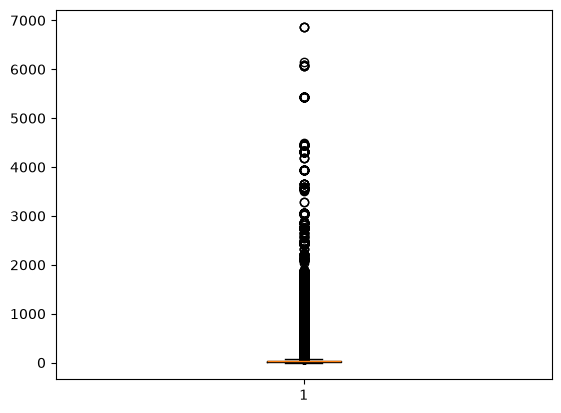

In [30]:
import matplotlib.pyplot as plt

plt.boxplot(training_data['amount_usd'])

{'bodies': [<matplotlib.collections.FillBetweenPolyCollection at 0x10ed28e00>],
 'cmaxes': <matplotlib.collections.LineCollection at 0x10ed9a6f0>,
 'cmins': <matplotlib.collections.LineCollection at 0x10edab710>,
 'cbars': <matplotlib.collections.LineCollection at 0x10eade9c0>}

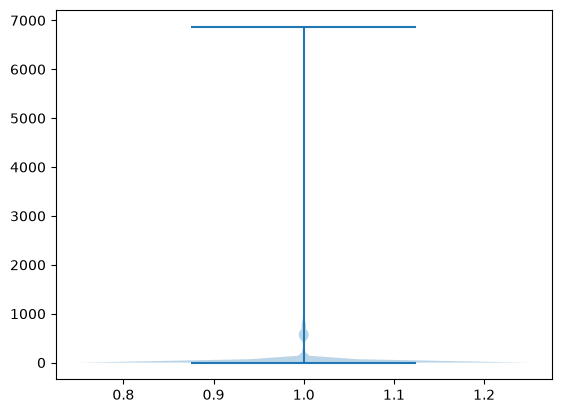

In [31]:
plt.violinplot(training_data['amount_usd'])

(array([6.40546e+05, 7.58900e+03, 2.41200e+03, 1.54220e+04, 1.50640e+04,
        8.61800e+03, 4.06000e+03, 2.60000e+03, 1.14500e+03, 1.04700e+03,
        2.22000e+02, 2.79000e+02, 3.44000e+02, 8.50000e+01, 1.00000e+00,
        3.10000e+01, 1.00000e+01, 3.80000e+01, 1.30000e+01, 5.00000e+00,
        1.59000e+02, 1.00000e+00, 5.40000e+01, 2.00000e+00, 0.00000e+00,
        1.70000e+01, 1.20000e+01, 0.00000e+00, 2.70000e+01, 0.00000e+00,
        3.00000e+00, 3.90000e+01, 7.30000e+01, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 3.20000e+01,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 7.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 3.00000e+00]),
 array([1.0000000e+00, 1.3843380e+02, 2.7586760e+02, 4.1330140e+02,
        5.5073520e+02, 6.8816900e+02, 8.2560280e+02, 9.6303660e+02,
        1.1004704e+03, 1.2379042e+03, 1.3753380e+03, 1.5127718e+03,
        1.6502056e+03, 1.7876394e+03, 1.9250732e+03, 2.0625070e+

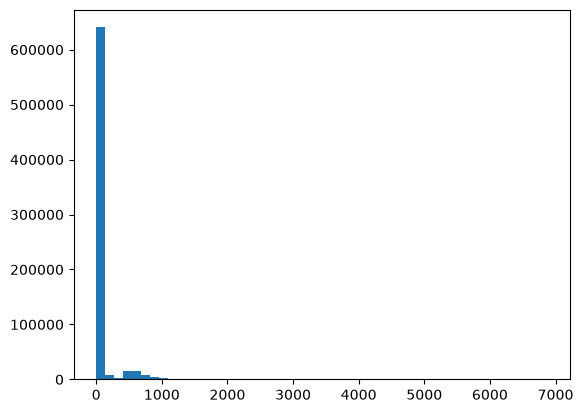

In [38]:
plt.hist(training_data['amount_usd'], bins=50)

<BarContainer object of 5 artists>

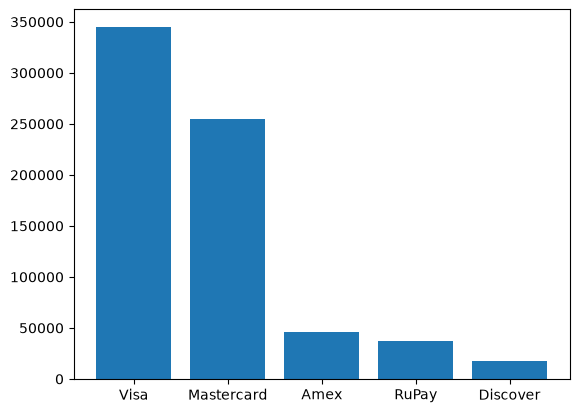

In [39]:
plt.bar(training_data['card_type'].value_counts().index, training_data['card_type'].value_counts().values)

<BarContainer object of 5 artists>

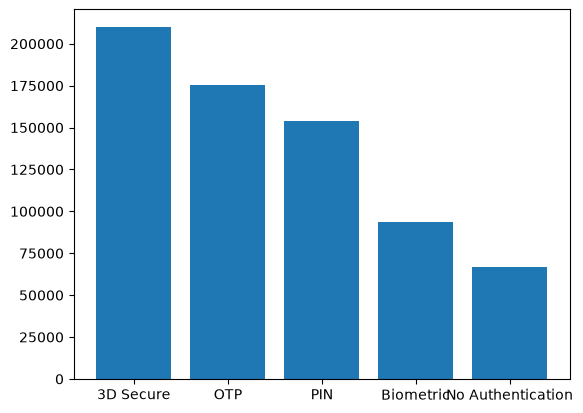

In [40]:
plt.bar(training_data['auth_method'].value_counts().index, training_data['auth_method'].value_counts().values)

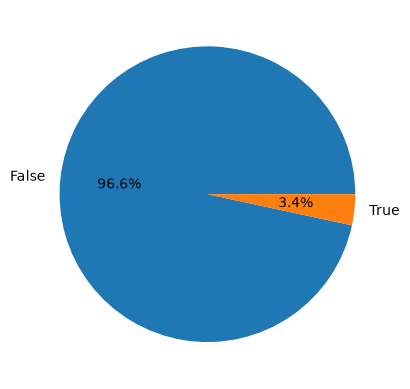

In [41]:
plt.pie(training_data['used_vpn'].value_counts().values, labels=training_data['used_vpn'].value_counts().index, autopct='%1.1f%%')

In [ ]:
# 5. Investigate relationships between variables (bivariate & multivariate analysis)


In [ ]:
# 6. Investigate relationship between explanatory variables and target variables